# 模块 D：交易策略与回测

评估区间 **2022-05 → 2026-11**，1133 个交易日——模块 C 信号的覆盖范围，也是五个策略唯一可比的时间段。

**要求项**：基于模块 C 信号的 B、C 都跑输买入持有 15.61%，最大回撤 −18.90% 与基准**完全相同**——信号没有改善回撤。

**扩展项**：E 用波动率和趋势定仓位，年化 15.94%、夏普 1.029、回撤 −17.71%，三个维度同时跑赢。

| 作业要求 | 位置 | 结论 |
|---|---|---|
| 基于模块 C 信号构建策略 | §1 B/C、§3 | 读 `signals/test_signals.csv` |
| 预测涨持有、跌空仓/做空 | §1 B、C | 两个变体都跑 |
| 基准 Buy & Hold | §3 A | 15.61% / 0.960 / −18.90% |
| 五个指标（年化/夏普/回撤/胜率/盈亏比） | §3 | 全给 |
| 关注最大回撤是否改善 | §4 | **B、C 均 +0.00pp** |
| ≥0.1% 单边成本 | §2 | `COST = 0.001` |
| 须用分类信号，不能用 MA 占位 | §1 | 用组员提交的 C 信号 |

## 0. 标的口径

S&P 500 是价格指数、不可交易。本回测是 **signal-level backtest**：按收盘价足额成交，检验规则本身的价值。实操对应 SPY（融资约 6%）或 ES 期货（约 3%）。全文按 **3% 融资 + 0.1% 单边成本**；指数不含股息，对高仓位策略略不利。

## 1. 五个策略

| 编号 | 仓位规则 | 角色 |
|---|---|---|
| A | 恒 1.0 | 基准 |
| **B** | 信号 1 → 满仓，0 → 空仓 | **要求项** |
| **C** | 信号 1 → 做多，0 → 做空 | **要求项** |
| D | 20% ÷ 40 日波动，**上限固定 1.75** | 扩展 |
| **E** | 20% ÷ 40 日波动，**上限随趋势：线上 1.4、线下 0.5** | **扩展** |

D、E 不预测方向，只用两个可估的量：**波动率**（现在多颠）和 **200 日线**（现在往哪走）。

**D 和 E 只差一个变量**：两者用同一个 40 日波动率、同一个 0.30 缓冲带，唯一区别是杠杆上限——D 固定 1.75，E 随趋势 1.4 / 0.5。所以两者的差异可以直接归因到“趋势约束”。

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'SP500_daily.csv').exists())
plt.rcParams.update({'font.sans-serif': ['PingFang SC', 'Arial Unicode MS'], 'axes.unicode_minus': False})
COST, RF, TV, BW = 0.001, 0.03, 0.20, 0.30        # 单边成本 / 融资年化 / 目标波动 / 换手缓冲带

In [2]:
close = pd.read_csv(ROOT / 'data/SP500_daily.csv', parse_dates=['Date']).set_index('Date')['Close']
fwd, lr = close.shift(-1) / close - 1, np.log(close).diff()                        # 次日收益、日对数收益
sig = pd.read_csv(ROOT / 'reports/2_RiseFallForecast/signals/test_signals.csv', parse_dates=['signal_date'])
s, T = sig.set_index('signal_date')['pred_up'].reindex(close.index).fillna(0), close.index >= sig.signal_date.min()
print(f'评估 {T.sum()} 天｜{close.index[T][0].date()} → {close.index[T][-1].date()}｜信号持仓率 {sig.pred_up.mean():.1%}')

评估 1133 天｜2022-05-11 → 2026-11-13｜信号持仓率 95.4%


In [3]:
def band(x, w=BW):
    p, cur = np.zeros(len(x)), 0.
    for i, v in enumerate(x):
        cur = v if abs(v - cur) > w else cur          # 差超 30% 才调仓，压住换手
        p[i] = cur
    return p


vol = (lr.rolling(40).std() * np.sqrt(252)).fillna(TV).values               # 近 40 日年化波动率
trend = close.values > close.rolling(200).mean().values                      # 收盘在 200 日线上方
pos = {'A': np.ones(len(close)), 'B': s.values, 'C': np.where(s.values == 1, 1., -1.),
       'D': band(np.minimum(TV / vol, 1.75)),                                # 上限固定 1.75
       'E': band(np.minimum(TV / vol, np.where(trend, 1.40, .50)))}          # 上限随趋势

## 2. 回测：四条规则

1. **时点对齐**：`fwd` 用 `shift(-1)`，t 日收盘定仓位，赚 t→t+1 的收益。
2. **换手计费**：`|Δ仓位| × 0.1%`，建仓、平仓、反手都收。
3. **杠杆计费**：超过 1 倍的部分按 3% 年化收融资成本。
4. **净值与回撤**：净收益累乘得净值，再除以历史最高点减一。

净收益 = **仓位 × 次日收益 − 换手成本 − 融资成本**，就这一行。

In [4]:
def netof(p, m):
    p, r = pd.Series(p, index=close.index)[m].fillna(0).values, fwd[m].fillna(0).values
    return p, p * r - np.abs(np.diff(p, prepend=0)) * COST - np.maximum(p - 1, 0) * RF / 252


def perf(p, m):
    p, net = netof(p, m)
    eq = np.cumprod(1 + net); dd = (eq / np.maximum.accumulate(eq) - 1).min()
    blk = pd.Series(p).ne(pd.Series(p).shift()).cumsum()                 # 同一笔持仓编组
    tr = pd.Series(net).groupby(blk).apply(lambda x: (1 + x).prod() - 1)[pd.Series(p).groupby(blk).first() != 0]
    cagr = eq[-1] ** (252 / len(net)) - 1
    return dict(年化=cagr, 夏普=net.mean() / net.std() * np.sqrt(252), 回撤=dd, 卡玛=cagr / abs(dd),
                胜率=(tr > 0).mean(), 盈亏比=tr[tr > 0].mean() / abs(tr[tr < 0].mean()), 笔数=len(tr), 终值=eq[-1])

## 3. 绩效指标表

In [5]:
tab = pd.DataFrame({k: perf(v, T) for k, v in pos.items()}).T
tab.index = ['A 买入持有', 'B 信号 多/空仓', 'C 信号 多/空', 'D 波动率目标', 'E 波动率+趋势']
tab['回撤改善(pp)'] = ((tab['回撤'] - tab.loc['A 买入持有', '回撤']) * 100).round(2)
tab.round(4)

,年化,夏普,回撤,卡玛,胜率,盈亏比,笔数,终值,回撤改善(pp)
A 买入持有,0.1561,0.9596,-0.1890,0.8258,1.0000,NaN,1.0,1.9196,0.00
B 信号 多/空仓,0.1427,0.8996,-0.1890,0.7550,0.9444,0.4582,18.0,1.8218,0.00
C 信号 多/空,0.1286,0.8132,-0.1890,0.6803,0.6389,2.2065,36.0,1.7227,0.00
D 波动率目标,0.1847,0.9541,-0.2471,0.7473,0.7000,2.7229,10.0,2.1424,-5.81
E 波动率+趋势,0.1594,1.0294,-0.1771,0.9002,0.6667,3.7468,21.0,1.9446,1.19


## 4. 最大回撤是否改善（作业重点关注）

上表最后一列就是答案：**B 和 C 改善 +0.00pp**——与基准完全相同。这是本次作业最重要的负面结论。

## 5. 为什么 B/C 零改善，E 却可以

**问题不在模型准不准，在仓位结构。** B 有 95.4% 的交易日都在持仓，2025 年 2–4 月那次急跌它一天都没让空仓，所以回撤曲线与基准完全重合。它胜率 94.4%，但盈亏比只有 0.46——赚一次赚一点，亏一次亏更多，年化因此掉到 14.27%。C 加了做空也没改善，因为低分位的日子没有系统性下跌。

**E 的改动只有一条：给杠杆上限加上趋势条件。** 波动率规则、缓冲带、其余全部与 D 相同。

| | D | E |
|---|---|---|
| 波动率 | 40 日 | 40 日（相同） |
| 缓冲带 | 0.30 | 0.30（相同） |
| **杠杆上限** | **固定 1.75** | **线上 1.4 / 线下 0.5** |
| 年化 | 18.47% | 15.94% |
| 最大回撤 | **−24.71%** | **−17.71%** |

**同一条波动率规则，只加一个趋势约束，回撤改善 7.00 个百分点**，代价是收益少 2.53pp、平均仓位从 1.33 降到 1.11。

**证据：2025 年 2–4 月那次急跌（一个月 −18.98%）。** D 的波动率是事后算的，跌出来才升上去，那时还挂着 1.33 倍，亏 24.83%；E 在跌破 200 日线时就降到 0.5 档，平均仓位 0.88 倍，只亏 17.82%——比满仓基准还少。

In [6]:
m = (close.index >= '2025-02-19') & (close.index <= '2025-04-07')
pd.DataFrame({k: [f'{netof(pos[k], m)[0].mean():.2f}x', f'{(1 + netof(pos[k], m)[1]).prod() - 1:.2%}'] for k in 'ADE'},
             index=['均仓位', '区间收益']).T

,均仓位,区间收益
A,1.00x,-18.98%
D,1.33x,-24.83%
E,0.88x,-17.82%


## 6. 净值与回撤

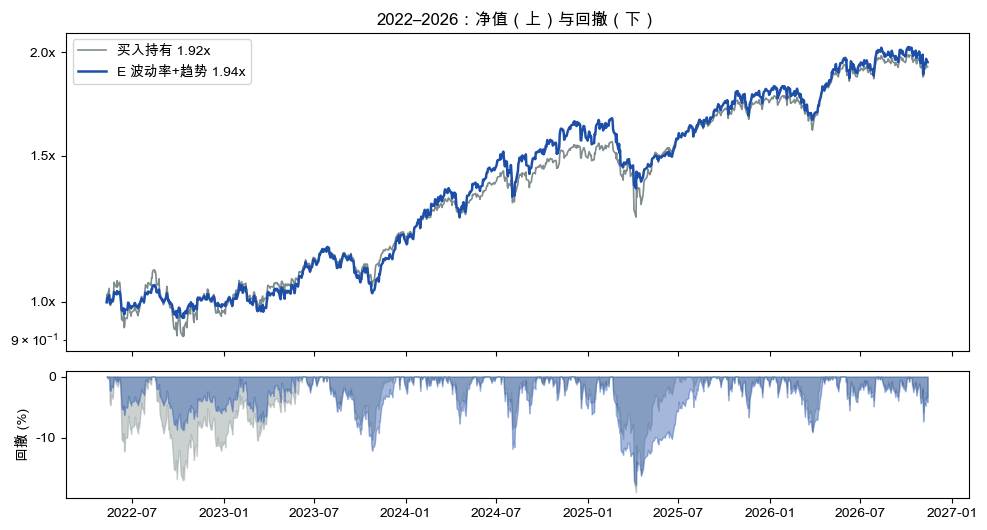

In [7]:
eq = {k: pd.Series(np.cumprod(1 + netof(pos[k], T)[1]), index=close.index[T]) for k in 'AE'}
fig, ax = plt.subplots(2, 1, figsize=(10, 5.4), sharex=True, gridspec_kw={'height_ratios': [3, 1.2]})
for k, c, nm in [('A', '#7f8c8d', '买入持有'), ('E', '#1E4FA8', 'E 波动率+趋势')]:
    ax[0].plot(eq[k], color=c, label=f'{nm} {eq[k].iloc[-1]:.2f}x', lw=1.8 if k == 'E' else 1.2)
    ax[1].fill_between(eq[k].index, (eq[k] / eq[k].cummax() - 1) * 100, 0, color=c, alpha=.4)
ax[0].set_yscale('log'); ax[0].set_yticks([1, 1.5, 2], ['1.0x', '1.5x', '2.0x']); ax[0].legend(); ax[0].set_title('2022–2026：净值（上）与回撤（下）'); ax[1].set_ylabel('回撤 (%)')
plt.tight_layout()
plt.savefig(ROOT / 'reports/3_TradingStrategy_Backtesting/equity_drawdown.png', dpi=130, bbox_inches='tight'); plt.show()

## 7. 结论

**要求项**

1. **分类信号无效**：B 年化 14.27%、C 12.86%，都跑输基准 15.61%。
2. **回撤零改善**：B、C 的最大回撤 −18.90% 与基准完全相同。B 有 95.4% 时间满仓，2025 年急跌一天没空仓；C 加做空也没改善。
3. **原因**：胜率 94.4% 但盈亏比 0.46，赚小亏大——既躲不开下跌，也抓不住上涨。

**扩展项**

4. **只加杠杆不行**：D 收益 18.47%，但回撤恶化到 −24.71%，夏普 0.954、卡玛 0.747 都低于基准。
5. **E 三个维度同时赢**：15.94% 对 15.61%、夏普 1.029 对 0.960、回撤 −17.71% 对 −18.90%、卡玛 0.900 对 0.826。
6. **代价**：平均仓位 1.11 倍，超额依赖 3% 融资；涨到 4.5% 收益优势消失，但回撤和夏普仍领先。

**局限**

7. 只用一个区间（4.5 年）评估，且是偏强的牛市，基准 15.61% 本身很高；换到更长样本或高波动年代，结论可能不同。**这是本报告最需要补充的部分。**